<a href="https://colab.research.google.com/github/Prajwaln08/SQLSmith/blob/main/notebooks/10_SFT_Comparative_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SQLSmith — Notebook 10 | Official SFT Comparative Evaluation

**Milestone B** · Frozen base vs QLoRA SFT · Full Spider 1.0 dev (1,034 questions) · Official augmented test-suite evaluation

**Three independent runs** in this notebook:
1. **T4 GPU:** set `STAGE='generate'`, `MODEL_CHOICE='1.5b'`; run Sections **1–7**.
2. **Restart session → T4 GPU:** set `MODEL_CHOICE='7b'`; run Sections **1–7**.
3. **CPU only:** set `STAGE='evaluate'`; run Sections **1–4, then 8–13**. **Skip Sections 5–7**.

This notebook **does not train** any models. It attaches previously saved LoRA adapters for inference. The frozen baseline prediction files from Notebook 06 remain unchanged. The original public Spider dev examples are not used for tuning or checkpoint selection.

**Important:** Notebook 09's main 200-step 7B adapter is required by default. Do not confuse the 10-step smoke-test adapter with the main trained adapter.

## 1 — Install evaluation/inference dependencies

This installation is compatible with the earlier 4.x QLoRA notebooks. Restart the Colab session only if you already imported older incompatible library versions before executing this cell.

In [1]:
%pip install -q -U "transformers>=4.56,<5" "peft>=0.17,<1" "accelerate>=1.10,<2" "bitsandbytes>=0.46.1" huggingface_hub pandas numpy nltk matplotlib safetensors

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2 — Mount Drive and configure this run

**Edit these two variables.** `STAGE='generate'` needs a GPU and loads **one** model. `STAGE='evaluate'` never loads a model.

If Google Drive is already mounted, do not force-remount. For a Drive mount error, use the Colab UI to reconnect before proceeding.

In [2]:

from pathlib import Path
import json

PROJECT = Path(
    "/content/drive/MyDrive/Prajwal/Projects/SQLSmith"
)

MODEL_ROOT = PROJECT / "models"

print("Searching for Qwen 7B LoRA adapters...\n")

found_adapters = []

for config_path in MODEL_ROOT.rglob("adapter_config.json"):
    adapter_dir = config_path.parent

    try:
        config = json.loads(config_path.read_text())
        base_model = config.get("base_model_name_or_path", "")
    except Exception:
        continue

    if "7B" not in base_model:
        continue

    weights = list(adapter_dir.glob("adapter_model.*"))

    if weights:
        found_adapters.append(adapter_dir)

        print("FOUND:", adapter_dir)
        print("Base model:", base_model)
        print("Weights:", [p.name for p in weights])
        print("-" * 60)

print("\nTotal 7B adapters found:", len(found_adapters))


Searching for Qwen 7B LoRA adapters...


Total 7B adapters found: 0


In [3]:
from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, csv, re, hashlib, time, zipfile, subprocess, gc, importlib.metadata
import numpy as np
import pandas as pd

STAGE = 'evaluate'        # 'generate' for each T4 run; 'evaluate' for CPU run
MODEL_CHOICE = '7b'     # FIRST GPU run: '1.5b'; SECOND GPU run: '7b'
START_INDEX = 1           # Inclusive. Use 1–1034 for complete evaluation.
END_INDEX = 1034
MAX_NEW_TOKENS = 256

assert STAGE in {'generate','evaluate'}
assert MODEL_CHOICE in {'1.5b','7b'}
assert 1 <= START_INDEX <= END_INDEX <= 1034

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/Prajwal/Projects/SQLSmith')
RESULTS = PROJECT/'results'
BASELINE_DIR = RESULTS/'full_spider'
NEW_DIR = RESULTS/'milestone_B'/'official_eval'
EVAL = PROJECT/'evaluation'/'sft_full_spider'
DATA = PROJECT/'data'
for directory in (NEW_DIR,EVAL): directory.mkdir(parents=True,exist_ok=True)

MODEL_IDS={'1.5b':'Qwen/Qwen2.5-Coder-1.5B-Instruct','7b':'Qwen/Qwen2.5-Coder-7B-Instruct'}
ADAPTER_PATHS={
    '1.5b':PROJECT/'models/qlora_1p5b_sft_v1/final_adapter',
    '7b':PROJECT/'models/qlora_7b_sft_v1/main_200/final_adapter',
}
# If Notebook 08/09 saved their final adapters somewhere else, edit ADAPTER_PATHS above.
BASELINE_CSVS={key:BASELINE_DIR/f'spider_{key}_full_dev_predictions.csv' for key in MODEL_IDS}
SFT_CSVS={key:NEW_DIR/f'spider_sft_{key}_full_dev_predictions.csv' for key in MODEL_IDS}
CHECKPOINTS={key:NEW_DIR/f'spider_sft_{key}_full_dev_checkpoint.jsonl' for key in MODEL_IDS}
RUN_CONFIGS={key:NEW_DIR/f'spider_sft_{key}_run_config.json' for key in MODEL_IDS}

# Strictly enforce that only the main 7B adapter is used.
assert 'main_200' in str(ADAPTER_PATHS['7b']), 'The 7B path must reference the main experiment.'

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as source:
        for block in iter(lambda:source.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

print('Stage:',STAGE,'| Model choice:',MODEL_CHOICE)
print('Project:',PROJECT)
print('Outputs:',NEW_DIR)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Mounted at /content/drive
Stage: evaluate | Model choice: 7b
Project: /content/drive/MyDrive/Prajwal/Projects/SQLSmith
Outputs: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_B/official_eval


## 3 — Load the exact Spider 1.0 development archive

Use the **same release and SHA256 check** as Notebook 06. The archived development questions and schema metadata must not change between frozen-baseline and SFT evaluations.

In [4]:
from huggingface_hub import hf_hub_download
SPIDER=Path('/content/sqlsmith_data/spider_data')
ARCHIVE=hf_hub_download(repo_id='HAL-9001/spider-databases',repo_type='dataset',filename='spider_data.zip')
EXPECTED_ARCHIVE_HASH='00636695dabed6b5f4b8328a16b13e069a2f16591d5efcce57660669c85b121b'
assert sha256_file(ARCHIVE)==EXPECTED_ARCHIVE_HASH,'Spider archive hash changed; stop and inspect.'
if not all((SPIDER/n).is_file() for n in ('dev.json','tables.json')):
    root=Path('/content/sqlsmith_data').resolve()
    root.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(ARCHIVE) as z:
        for entry in z.infolist():
            assert (root/entry.filename).resolve().is_relative_to(root),'Unsafe ZIP archive entry'
        z.extractall(root)
DEV_PATH=SPIDER/'dev.json'
TABLES_PATH=SPIDER/'tables.json'
dev=json.loads(DEV_PATH.read_text(encoding='utf-8'))
schemas={s['db_id']:s for s in json.loads(TABLES_PATH.read_text(encoding='utf-8'))}
assert len(dev)==1034 and len(set(r['db_id'] for r in dev))==20
assert all(r['db_id'] in schemas for r in dev)
print('PASS: 1034 original dev questions; 20 databases')
print('Spider dev SHA:',sha256_file(DEV_PATH))
print('Spider schema SHA:',sha256_file(TABLES_PATH))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


spider_data.zip:   0%|          | 0.00/206M [00:00<?, ?B/s]

PASS: 1034 original dev questions; 20 databases
Spider dev SHA: 30d64a3fccde493226df79687aed9e4a1c0129525baf44f29c0573d914d758a4
Spider schema SHA: 61bb20aa401f03164e2d7f3b16509b7b5f79cc9c943ca7bd159046df1159e2ed


## 4 — Reuse Notebook 06's exact full-schema prompt

Prompt wording, schema formatting, decoding and question ordering are frozen. Do not insert gold SQL, repair predicted SQL, add schema linking, or add test-time hints.

In [5]:
def get_spider_schema(db_id):
    item=schemas[db_id]
    tables=item['table_names_original']
    columns=item['column_names_original']
    types=item['column_types']
    output=[]
    for table_index, table_name in enumerate(tables):
        table_columns=[]
        for col_index,(idx,col_name) in enumerate(columns):
            if idx==table_index:
                table_columns.append(f'  {col_name} {types[col_index]}')
        output.append(f'Table: {table_name}\n'+'\n'.join(table_columns))
    output.append('\nForeign keys:')
    for col_a,col_b in item['foreign_keys']:
        ta,ca=columns[col_a]; tb,cb=columns[col_b]
        if ta>=0 and tb>=0: output.append(f'{tables[ta]}.{ca} = {tables[tb]}.{cb}')
    return '\n\n'.join(output)

SYSTEM_PROMPT=('You are an expert text-to-SQL assistant. '
               'Generate exactly one valid SQLite SELECT query. '
               'Use only the tables and columns in the schema. '
               'Return SQL only, without markdown or explanation.')

def make_messages(question,schema_text):
    return [
        {'role':'system','content':SYSTEM_PROMPT},
        {'role':'user','content':f'Schema:\n{schema_text}\n\nQuestion: {question}'}
    ]

# Check exact metadata alignment before either inference or scoring.
for key,path in BASELINE_CSVS.items():
    assert path.is_file(),f'Missing Notebook 06 baseline: {path}'
    frame=pd.read_csv(path,keep_default_na=False).sort_values('index')
    assert len(frame)==1034
    assert frame['index'].astype(int).tolist()==list(range(1,1035))
    for idx,r in enumerate(frame.itertuples(index=False)):
        assert r.db_id==dev[idx]['db_id'] and r.question==dev[idx]['question']
        assert ' '.join(str(r.gold_sql).split())==' '.join(dev[idx]['query'].split())
        assert r.model==MODEL_IDS[key]
    print('PASS: frozen baseline',key,sha256_file(path))
print('Original prompt is frozen. Ready for:',STAGE)

PASS: frozen baseline 1.5b 144e3f94ed55b3562f4cb9a73db9f0faa470407837ba983c90a4f2475fe86191
PASS: frozen baseline 7b efde8106130ae3dea89d4dbc4f53151a2371920f69cdf126385ec22ec9b7e610
Original prompt is frozen. Ready for: evaluate


## 5 — **GPU ONLY**: load the selected base model + saved LoRA adapter

Run **only when `STAGE='generate'`**. Run this section once for 1.5B, then restart runtime for 7B. Loading both models in one T4 session may exhaust memory.

Inference quantization uses the **same NF4 / fp16 / double-quant off** baseline settings from Notebook 06. Your adapters are trained with their own LoRA rank; PEFT reads this automatically from `adapter_config.json`.

In [6]:
assert STAGE=='generate','Skip Sections 5–7 during CPU-only scoring.'
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel
assert torch.cuda.is_available(),'Use Runtime > Change runtime type > T4 GPU.'

MODEL_ID=MODEL_IDS[MODEL_CHOICE]
ADAPTER_DIR=ADAPTER_PATHS[MODEL_CHOICE]
assert (ADAPTER_DIR/'adapter_config.json').is_file(),f'Missing trained adapter: {ADAPTER_DIR}'
weights=list(ADAPTER_DIR.glob('adapter_model.*'))
assert weights,f'Missing adapter weight file in {ADAPTER_DIR}'
adapter_meta=json.loads((ADAPTER_DIR/'adapter_config.json').read_text(encoding='utf-8'))
trained_base=adapter_meta.get('base_model_name_or_path')
assert trained_base==MODEL_ID,f'Adapter trained for {trained_base}, expected {MODEL_ID}'
ADAPTER_HASHES={p.name:sha256_file(p) for p in ADAPTER_DIR.iterdir() if p.is_file()}

# Never reuse a previously loaded base model or LoRA adapters in this notebook.
assert 'model' not in globals(), 'Model already loaded. Restart session before changing MODEL_CHOICE.'
qconfig=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
   bnb_4bit_compute_dtype=torch.float16,bnb_4bit_use_double_quant=False)
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,use_fast=True)
if tokenizer.pad_token is None: tokenizer.pad_token=tokenizer.eos_token
base=AutoModelForCausalLM.from_pretrained(MODEL_ID,quantization_config=qconfig,
    device_map={'':0},dtype=torch.float16,low_cpu_mem_usage=True)
model=PeftModel.from_pretrained(base,str(ADAPTER_DIR),is_trainable=False)
model.eval()
assert all(not p.requires_grad for p in model.parameters())
print('GPU:',torch.cuda.get_device_name(0))
print('Model:',MODEL_ID)
print('Adapter:',ADAPTER_DIR)
print('Adapter files SHA:',ADAPTER_HASHES)
print('GPU GiB allocated:',round(torch.cuda.memory_allocated()/2**30,3))

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:52: FutureWarning: Support for Transformers < 5.6 is deprecated in PEFT and will be removed in the next release, v1.0. You have Transformers 4.57.6. Please upgrade to Transformers >= 5.6.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

... (5 outputs left out)

model-00002-of-00004.safetensors:   0%|          | 0.00/4.93G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

GPU: Tesla T4
Model: Qwen/Qwen2.5-Coder-7B-Instruct
Adapter: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/models/qlora_7b_sft_v1/main_200/final_adapter
Adapter files SHA: {'README.md': '09f8b07f799ad0a4814510ad939e8beeab67d1d9d3babb3cb98ec9d4a0f3d286', 'adapter_model.safetensors': '178c55e80432de3664e442cf9eef6204cef4ceaee8751ab4a6fef833463ebe0d', 'adapter_config.json': 'ab4692c189a1d1788d339d1b7ab739bfc35138d98bd2052cab24624426c112bf', 'chat_template.jinja': 'cd8e9439f0570856fd70470bf8889ebd8b5d1107207f67a5efb46e342330527f', 'tokenizer_config.json': '60bf17d6543b028dbd97ac7f4847418c96502006b80b4b1c57427c241c818224', 'special_tokens_map.json': '76862e765266b85aa9459767e33cbaf13970f327a0e88d1c65846c2ddd3a1ecd', 'added_tokens.json': '58b54bbe36fc752f79a24a271ef66a0a0830054b4dfad94bde757d851968060b', 'vocab.json': 'ca10d7e9fb3ed18575dd1e277a2579c16d108e32f27439684afa0e10b1440910', 'merges.txt': '8831e4f1a044471340f7c0a83d7bd71306a5b867e95fd870f74d0c5308a904d5', 'tokenizer.json': '9c5a

## 6 — **GPU ONLY**: generation with resumable, immutable checkpoints

Runs the selected model across the original 1,034 examples without their gold SQL. Each successful generation is immediately appended to Google Drive. On a Colab disconnect, rerun setup and use **the same model + adapter + config**; saved successes are skipped.

**Do not change the adapter files once generation begins.** Run settings, adapter hashes and input hashes are checked before writing new results.

In [7]:
assert STAGE=='generate','Skip during CPU evaluation'
MODEL_ID=MODEL_IDS[MODEL_CHOICE]
CHECKPOINT=CHECKPOINTS[MODEL_CHOICE]
CFG_PATH=RUN_CONFIGS[MODEL_CHOICE]
CONFIG={
    'model_id':MODEL_ID,'adapter_dir':str(ADAPTER_DIR),
    'adapter_hashes':ADAPTER_HASHES,'inference_quantization':'nf4_4bit_fp16_double_quant_false',
    'max_new_tokens':MAX_NEW_TOKENS,'do_sample':False,
    'prompt_revision':'notebook01_full_schema_original',
    'dev_sha256':sha256_file(DEV_PATH),'tables_sha256':sha256_file(TABLES_PATH),
    'baseline_csv_sha256':sha256_file(BASELINE_CSVS[MODEL_CHOICE]),
}
if CFG_PATH.is_file():
    assert json.loads(CFG_PATH.read_text(encoding='utf-8'))==CONFIG, (
        'Checkpoint configuration changed. Do not mix adapters or configs; archive old experiment first.')
else:
    assert not CHECKPOINT.exists(),'Checkpoint exists without matching run config. Stop and investigate.'
    CFG_PATH.write_text(json.dumps(CONFIG,indent=2),encoding='utf-8')

def load_checkpoint(path):
    done={}
    if not path.exists(): return done
    for lineno,line in enumerate(path.read_text(encoding='utf-8').splitlines(),1):
        if not line.strip(): continue
        try:r=json.loads(line)
        except json.JSONDecodeError:
            print('Warning: unparsable checkpoint line',lineno); continue
        idx=int(r['index'])
        assert 1<=idx<=len(dev)
        assert r['db_id']==dev[idx-1]['db_id'] and r['question']==dev[idx-1]['question']
        assert r['model']==MODEL_ID and r['adapter_sha256']==ADAPTER_HASHES.get('adapter_model.safetensors',ADAPTER_HASHES.get('adapter_model.bin'))
        if r['status']=='ok':
            assert isinstance(r.get('predicted_sql'),str)
            if idx in done: assert done[idx]['predicted_sql']==r['predicted_sql'],'Duplicate index differs'
            done[idx]=r
    return done

def generate_one(item):
    prompt=tokenizer.apply_chat_template(
        make_messages(item['question'],get_spider_schema(item['db_id'])),
        tokenize=False,add_generation_prompt=True)
    inputs=tokenizer(prompt,return_tensors='pt',add_special_tokens=False)
    input_ids=inputs['input_ids'].to(model.device)
    attention_mask=inputs['attention_mask'].to(model.device)
    torch.cuda.synchronize()
    started=time.perf_counter()
    with torch.inference_mode():
        outputs=model.generate(input_ids=input_ids,attention_mask=attention_mask,
            max_new_tokens=MAX_NEW_TOKENS,do_sample=False,
            pad_token_id=tokenizer.eos_token_id)
    torch.cuda.synchronize()
    elapsed=time.perf_counter()-started
    gen_ids=outputs[0,input_ids.shape[-1]:]
    return tokenizer.decode(gen_ids,skip_special_tokens=True).strip(),elapsed,int(gen_ids.numel()),int(input_ids.shape[-1])

completed=load_checkpoint(CHECKPOINT)
print(f'Resuming {MODEL_CHOICE}: {len(completed)}/1034 previously saved')
for idx in range(START_INDEX,END_INDEX+1):
    if idx in completed: continue
    item=dev[idx-1]
    try:
        sql,latency,n_out,n_in=generate_one(item)
        row={'index':idx,'db_id':item['db_id'],'question':item['question'],
             'predicted_sql':sql,'latency_seconds':round(latency,6),
             'output_tokens':n_out,'input_tokens':n_in,'model':MODEL_ID,
             'adapter_sha256':ADAPTER_HASHES.get('adapter_model.safetensors',ADAPTER_HASHES.get('adapter_model.bin')),
             'status':'ok','error':'','timestamp_utc':datetime.now(timezone.utc).isoformat()}
    except Exception as exc:
        row={'index':idx,'db_id':item['db_id'],'question':item['question'],
             'predicted_sql':'','latency_seconds':None,'output_tokens':None,'input_tokens':None,
             'model':MODEL_ID,'adapter_sha256':ADAPTER_HASHES.get('adapter_model.safetensors',ADAPTER_HASHES.get('adapter_model.bin')),
             'status':'error','error':repr(exc),'timestamp_utc':datetime.now(timezone.utc).isoformat()}
    with CHECKPOINT.open('a',encoding='utf-8') as target:
        target.write(json.dumps(row,ensure_ascii=False)+'\n')
        target.flush(); os.fsync(target.fileno())
    if row['status']!='ok':raise RuntimeError(f'Generation failed at {idx}: {row["error"]}')
    completed[idx]=row
    if idx<=5 or idx%20==0 or idx==END_INDEX:
        print(f'[{idx}/{END_INDEX}] {MODEL_CHOICE} saved; {row["latency_seconds"]:.2f}s')
print('Checkpoint:',len(completed),'/1034 successfully completed')

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Resuming 7b: 0/1034 previously saved
[1/1034] 7b saved; 7.62s
[2/1034] 7b saved; 0.80s
[3/1034] 7b saved; 1.76s
[4/1034] 7b saved; 1.79s
[5/1034] 7b saved; 3.13s
[20/1034] 7b saved; 2.16s
[40/1034] 7b saved; 1.79s
[60/1034] 7b saved; 12.71s
[80/1034] 7b saved; 5.48s
[100/1034] 7b saved; 7.13s
[120/1034] 7b saved; 6.64s
[140/1034] 7b saved; 3.91s
[160/1034] 7b saved; 3.12s
[180/1034] 7b saved; 1.88s
[200/1034] 7b saved; 2.41s
[220/1034] 7b saved; 8.46s
[240/1034] 7b saved; 9.23s
[260/1034] 7b saved; 1.01s
[280/1034] 7b saved; 4.14s
[300/1034] 7b saved; 2.03s
[320/1034] 7b saved; 2.12s
[340/1034] 7b saved; 4.37s
[360/1034] 7b saved; 4.33s
[380/1034] 7b saved; 3.74s
[400/1034] 7b saved; 5.90s
[420/1034] 7b saved; 6.16s
[440/1034] 7b saved; 1.24s
[460/1034] 7b saved; 6.24s
[480/1034] 7b saved; 1.99s
[500/1034] 7b saved; 6.67s
[520/1034] 7b saved; 2.05s
[540/1034] 7b saved; 6.82s
[560/1034] 7b saved; 6.16s
[580/1034] 7b saved; 1.91s
[600/1034] 7b saved; 2.20s
[620/1034] 7b saved; 2.20s
[640

## 7 — **GPU ONLY**: export model-specific full-dev predictions

This is the handoff to the separate CPU scorer. Both prediction CSVs need **1,034 rows each** before you begin the official evaluation.

In [8]:
assert STAGE=='generate'
completed=load_checkpoint(CHECKPOINT)
rows=[]
for idx in sorted(completed):
    r=completed[idx]
    rows.append({'index':idx,'db_id':r['db_id'],'question':r['question'],
      'gold_sql':dev[idx-1]['query'],'predicted_sql':r['predicted_sql'],
      'latency_seconds':r['latency_seconds'],'output_tokens':r['output_tokens'],
      'input_tokens':r['input_tokens'],'model':MODEL_ID,'adapter_dir':str(ADAPTER_DIR)})
frame=pd.DataFrame(rows)
assert frame['index'].is_unique if len(frame) else True
out_file=SFT_CSVS[MODEL_CHOICE]
frame.to_csv(out_file,index=False)
print('Rows exported:',len(frame),'of 1034')
print('Complete:',len(frame)==1034)
print('CSV:',out_file)
print('SHA256:',sha256_file(out_file))
if len(frame):
    latency=pd.to_numeric(frame['latency_seconds'],errors='coerce')
    tokens=pd.to_numeric(frame['output_tokens'],errors='coerce')
    print('Mean latency:',round(latency.mean(),3),'s')
    print('p95 latency:',round(latency.quantile(.95),3),'s')
    print('Mean generated tokens/s:',round((tokens/latency.replace(0,np.nan)).mean(),2))
    print('Peak GPU memory (GiB):',round(torch.cuda.max_memory_allocated()/2**30,3))

Rows exported: 1034 of 1034
Complete: True
CSV: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_B/official_eval/spider_sft_7b_full_dev_predictions.csv
SHA256: 2981b0a8e0514e74e30596e293a1df32c86369abe27653362845238cd4663986
Mean latency: 3.915 s
p95 latency: 8.475 s
Mean generated tokens/s: 8.08
Peak GPU memory (GiB): 6.586


## 8 — **CPU ONLY**: verify both SFT predictions and frozen baselines

**Restart Colab in CPU mode.** Run Sections **1–4**, then **8–13**. **Do not run Sections 5–7**. This evaluation will fail (deliberately) if either trained model lacks 1,034 complete predictions.

In [6]:
assert STAGE=='evaluate','Switch STAGE to evaluate; skip model-loading and generation sections.'
PREDICTIONS={}
for key in MODEL_IDS:
    for variant,path in [('base',BASELINE_CSVS[key]),('sft',SFT_CSVS[key])]:
        assert path.is_file(),f'Missing {variant} {key} prediction CSV: {path}'
        frame=pd.read_csv(path,keep_default_na=False)
        assert len(frame)==1034,f'{variant} {key}: {len(frame)}/1034 predictions; complete generation first.'
        frame['index']=pd.to_numeric(frame['index'],errors='raise').astype(int)
        frame=frame.sort_values('index').reset_index(drop=True)
        assert frame['index'].tolist()==list(range(1,1035))
        assert frame['index'].is_unique
        for i,r in frame.iterrows():
            item=dev[i]
            assert r['db_id']==item['db_id'] and r['question']==item['question']
            assert ' '.join(str(r['gold_sql']).split())==' '.join(item['query'].split())
            assert r['model']==MODEL_IDS[key],f'Wrong underlying model at row {i+1}'
        if variant=='sft':
            expected=str(ADAPTER_PATHS[key])
            assert frame['adapter_dir'].eq(expected).all(),f'Wrong adapter for {key}'
            assert RUN_CONFIGS[key].is_file(),f'Missing generation config: {RUN_CONFIGS[key]}'
            conf=json.loads(RUN_CONFIGS[key].read_text(encoding='utf-8'))
            assert conf['model_id']==MODEL_IDS[key]
            assert conf['dev_sha256']==sha256_file(DEV_PATH)
            assert conf['tables_sha256']==sha256_file(TABLES_PATH)
            assert conf['baseline_csv_sha256']==sha256_file(BASELINE_CSVS[key])
        PREDICTIONS[(key,variant)]=frame
        print('PASS:',key,variant,'1034 rows; CSV SHA',sha256_file(path))
print('All 4 predictions sets aligned to exact Spider dev rows.')

PASS: 1.5b base 1034 rows; CSV SHA 144e3f94ed55b3562f4cb9a73db9f0faa470407837ba983c90a4f2475fe86191
PASS: 1.5b sft 1034 rows; CSV SHA 2903ca0b9cd0c2664c85494e885493fb1ff91e02f760ef6552ae07cb928a41c8
PASS: 7b base 1034 rows; CSV SHA efde8106130ae3dea89d4dbc4f53151a2371920f69cdf126385ec22ec9b7e610
PASS: 7b sft 1034 rows; CSV SHA 2981b0a8e0514e74e30596e293a1df32c86369abe27653362845238cd4663986
All 4 predictions sets aligned to exact Spider dev rows.


## 9 — Official evaluator and augmented test-suite databases

Pinned evaluator commit and flags are copied from Notebook 06. The test-suite ZIP already saved in your Google Drive is required; original Spider databases alone **are not** an equivalent substitute.

In [7]:
import nltk
nltk.download('punkt',quiet=True)
nltk.download('punkt_tab',quiet=True)
assert nltk.data.find('tokenizers/punkt_tab/english/')
EVALUATOR_REPO=Path('/content/test-suite-sql-eval')
EVALUATOR_COMMIT='e97acc546ecbee8fa27fa8dbf025ef61493a876c'
if not (EVALUATOR_REPO/'.git').is_dir():
    subprocess.run(['git','clone','https://github.com/taoyds/test-suite-sql-eval.git',str(EVALUATOR_REPO)],check=True)
subprocess.run(['git','-C',str(EVALUATOR_REPO),'checkout','--detach',EVALUATOR_COMMIT],check=True)
assert subprocess.check_output(['git','-C',str(EVALUATOR_REPO),'rev-parse','HEAD'],text=True).strip()==EVALUATOR_COMMIT
DRIVE_ZIP=DATA/'testsuitedatabases.zip'
LOCAL_ZIP=Path('/content/testsuitedatabases.zip')
ZIP=DRIVE_ZIP if DRIVE_ZIP.is_file() else LOCAL_ZIP
assert ZIP.is_file(),f'Missing augmented test-suite ZIP at {DRIVE_ZIP}'
assert zipfile.is_zipfile(ZIP)
EXPECTED_SUITE_ZIP_HASH='9ec24ea8debc6bd04abfe137b5f1a739b5a8836f32c0464e4dfc94eb7f41da96'
assert sha256_file(ZIP)==EXPECTED_SUITE_ZIP_HASH,'Test-suite ZIP differs from Notebook 06. Stop: do not compare mismatched evaluations.'
SUITES=Path('/content/sqlsmith_test_suites')
SUITES.mkdir(parents=True,exist_ok=True)
with zipfile.ZipFile(ZIP) as z:
    root=SUITES.resolve()
    for entry in z.infolist():assert (root/entry.filename).resolve().is_relative_to(root),'Unsafe ZIP entry'
    z.extractall(root)
required_ids=set(r['db_id'] for r in dev)
possible=[]
for anchor in list(required_ids)[:5]:
    for f in SUITES.rglob(f'{anchor}.sqlite'):
        if f.parent.name!=anchor:continue
        base=f.parent.parent
        if all((base/d/f'{d}.sqlite').is_file() for d in required_ids):possible.append(base)
assert possible,'Missing full augmented test-suite databases'
def suite_count(base):return sum(len(list((base/d).glob('*.sqlite'))) for d in required_ids)
SUITE_DB_ROOT=max(possible,key=suite_count)
assert sum(suite_count(SUITE_DB_ROOT)>0 for _ in [0])==1
assert sum(len(list((SUITE_DB_ROOT/d).glob('*.sqlite')))>1 for d in required_ids)>1
print('Evaluator commit:',EVALUATOR_COMMIT)
print('Official augmented suite root:',SUITE_DB_ROOT)
print('Suite SHA:',sha256_file(ZIP))

Evaluator commit: e97acc546ecbee8fa27fa8dbf025ef61493a876c
Official augmented suite root: /content/sqlsmith_test_suites/database
Suite SHA: 9ec24ea8debc6bd04abfe137b5f1a739b5a8836f32c0464e4dfc94eb7f41da96


## 10 — Write gold and prediction files (fixed ordering)

One gold file is generated from original Spider metadata and reused for all four runs. Predicted SQL is copied verbatim aside from flattening whitespace; **no post-generation SQL correction**.

In [8]:
def one_line(value):return ' '.join(str(value).split())
GOLD=EVAL/'spider_full_gold.txt'
gold_lines=[one_line(r['query'])+'\t'+r['db_id'] for r in dev]
GOLD.write_text('\n'.join(gold_lines)+'\n',encoding='utf-8')
PRED_FILES={}
for (key,variant),frame in PREDICTIONS.items():
    prediction_file=EVAL/f'spider_{key}_{variant}_predictions.txt'
    lines=[one_line(x) for x in frame['predicted_sql']]
    assert len(lines)==1034
    prediction_file.write_text('\n'.join(lines)+'\n',encoding='utf-8')
    PRED_FILES[(key,variant)]=prediction_file
    print(key,variant,'empty predictions:',sum(not x for x in lines),
          'SHA:',sha256_file(prediction_file))
print('Canonical gold SHA:',sha256_file(GOLD))

1.5b base empty predictions: 0 SHA: 3b8ada69c9eca989e6e7e907d065a297a0d0e24eb09be2fd5746195aedf0f96a
1.5b sft empty predictions: 0 SHA: 390aaae5ba6d19ed3c1a2f481ed6bf69aa5c2a080d4a84e6f182c03a64ffcf08
7b base empty predictions: 0 SHA: 52c405da8ee9ca4b84e63f390dbf54d7f9571f53983bf08beca4bbac0f0b7b73
7b sft empty predictions: 0 SHA: 045b18bcd3f487085a227637d393426bb4f17a6175ad33785bf38b977d30db9a
Canonical gold SHA: 3d941fdb2e6f330a27eae31bf59d594441fa140ee162a50800ee66c090b8b643


## 11 — Run pinned official test-suite evaluation on all four prediction sets

Uses `--etype exec` **without** `--plug_value` and **without** `--keep_distinct`, identical to Notebook 06. Official evaluator logs are retained. This section may take substantial CPU time.

In [9]:
EVAL_RESULTS={}
for key,variant in [('1.5b','base'),('1.5b','sft'),('7b','base'),('7b','sft')]:
    pred_file=PRED_FILES[(key,variant)]
    log_file=EVAL/f'spider_{key}_{variant}_official.log'
    cmd=[sys.executable,str(EVALUATOR_REPO/'evaluation.py'),
         '--gold',str(GOLD),'--pred',str(pred_file),
         '--etype','exec','--db',str(SUITE_DB_ROOT),'--table',str(TABLES_PATH)]
    started=time.monotonic()
    proc=subprocess.run(cmd,cwd=str(EVALUATOR_REPO),capture_output=True,text=True,timeout=7200)
    elapsed=round(time.monotonic()-started,2)
    log_file.write_text('COMMAND: '+' '.join(cmd)+'\nSTDOUT:\n'+proc.stdout+'\nSTDERR:\n'+proc.stderr,encoding='utf-8')
    print('MODEL:',key,variant,'| exit:',proc.returncode,'| elapsed:',elapsed,'s')
    print(proc.stdout[-1700:])
    if proc.returncode:print('STDERR tail:',proc.stderr[-1600:])
    assert proc.returncode==0,f'Evaluation failed. Inspect: {log_file}'
    lines=proc.stdout.splitlines()
    header=next((i for i,line in enumerate(lines) if 'EXECUTION ACCURACY' in line),None)
    assert header is not None,f'Missing official execution table: {log_file}'
    score_line=next((line for line in lines[header+1:] if re.match(r'^\s*execution\s+',line)),None)
    assert score_line,f'Missing execution row in {log_file}'
    fields=score_line.strip().split()
    assert len(fields)>=6,f'Unrecognized evaluator row: {score_line}'
    scores=dict(zip(['easy','medium','hard','extra','all'],map(float,fields[1:6])))
    EVAL_RESULTS[(key,variant)]={'accuracy':scores['all'],
        'scores_by_difficulty':scores,'elapsed_seconds':elapsed,'log_file':str(log_file)}
    print('Official execution accuracy:',f'{100*scores["all"]:.2f}%')
assert len(EVAL_RESULTS)==4

MODEL: 1.5b base | exit: 0 | elapsed: 33.33 s
                     easy                 medium               hard                 extra                all                 
count                248                  446                  174                  166                  1034                
=====================   EXECUTION ACCURACY     =====================
execution            0.653                0.408                0.259                0.301                0.425               

Official execution accuracy: 42.50%
MODEL: 1.5b sft | exit: 0 | elapsed: 34.29 s
                     easy                 medium               hard                 extra                all                 
count                248                  446                  174                  166                  1034                
=====================   EXECUTION ACCURACY     =====================
execution            0.831                0.612                0.425                0.367               

## 12 — Persist official comparison, reproducibility manifest and chart

**Accuracy is derived from the official evaluator output, not from comparing SQL strings.** Previous published Notebook 06 scores (42.5% / 73.2%) should match the re-scored baselines within the evaluator's printed rounding precision. A mismatch is a red flag; investigate before claiming improvements.

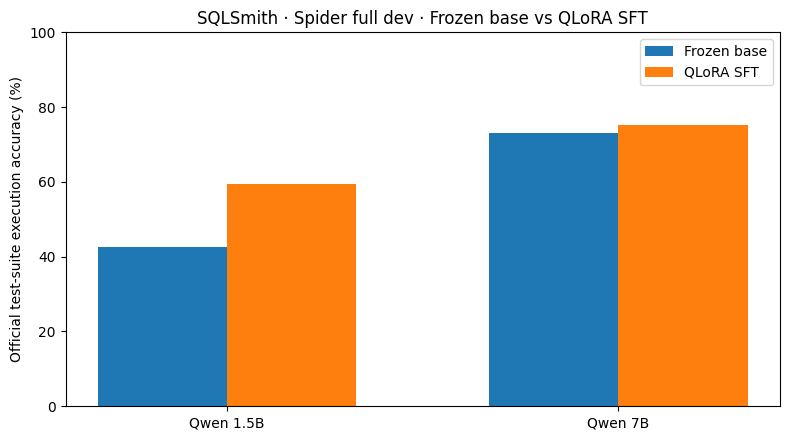


Official results:


,model,variant,official_test_suite_accuracy,accuracy_percent,mean_generation_latency_seconds,p95_generation_latency_seconds,mean_generated_tokens_per_second,empty_predictions
0,1.5b,base,0.425,42.5,1.810689,3.287060,20.166006,0
1,1.5b,sft,0.594,59.4,3.614564,7.580186,9.314188,0
2,7b,base,0.732,73.2,1.903786,3.665701,14.975681,0
3,7b,sft,0.751,75.1,3.914940,8.474822,8.076317,0



SFT gain / loss:


,model,baseline_accuracy,sft_accuracy,delta_percentage_points
0,1.5b,0.425,0.594,16.9
1,7b,0.732,0.751,1.9


Report: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_B/official_eval/10_sft_official_comparison_report.json
Summary: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_B/official_eval/10_sft_official_full_dev_summary.csv
Delta: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_B/official_eval/10_sft_vs_base_deltas.csv
Chart: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_B/official_eval/10_sft_official_accuracy_comparison.png


In [10]:
import matplotlib.pyplot as plt
records=[]
for key in ('1.5b','7b'):
    for variant in ('base','sft'):
        frame=PREDICTIONS[(key,variant)]
        latency=pd.to_numeric(frame['latency_seconds'],errors='coerce')
        tokens=pd.to_numeric(frame['output_tokens'],errors='coerce')
        scores=EVAL_RESULTS[(key,variant)]
        records.append({'model':key,'variant':variant,
            'official_test_suite_accuracy':scores['accuracy'],
            'accuracy_percent':round(100*scores['accuracy'],2),
            'mean_generation_latency_seconds':float(latency.mean()),
            'p95_generation_latency_seconds':float(latency.quantile(0.95)),
            'mean_generated_tokens_per_second':float((tokens/latency.replace(0,np.nan)).mean()),
            'empty_predictions':int((frame['predicted_sql']=='').sum()),
        })
summary=pd.DataFrame(records)
EXPECTED_BASELINE={'1.5b':0.425,'7b':0.732}
for key,ref in EXPECTED_BASELINE.items():
    observed=float(summary.loc[(summary.model==key)&(summary.variant=='base'),'official_test_suite_accuracy'].iloc[0])
    assert abs(observed-ref)<=0.001,(
        f'Baseline re-evaluation for {key} differs: {observed} vs expected {ref}. '
        'Check archive, evaluator, flags and prediction hashes before comparison.')
comparison=[]
for key in ('1.5b','7b'):
    base=EVAL_RESULTS[(key,'base')]['accuracy']
    sft=EVAL_RESULTS[(key,'sft')]['accuracy']
    comparison.append({'model':key,'baseline_accuracy':base,'sft_accuracy':sft,
        'delta_percentage_points':round(100*(sft-base),2)})
delta=pd.DataFrame(comparison)
SUMMARY_CSV=NEW_DIR/'10_sft_official_full_dev_summary.csv'
DELTA_CSV=NEW_DIR/'10_sft_vs_base_deltas.csv'
summary.to_csv(SUMMARY_CSV,index=False)
delta.to_csv(DELTA_CSV,index=False)

report={
    'project':'SQLSmith','notebook':'10_SFT_Comparative_Evaluation',
    'evaluation_scope':'Spider 1.0 dev 1034 examples, 20 databases',
    'caveat':'Dev-set evaluation; not held-out test. No hyperparameter selection using Spider dev.',
    'evaluator_commit':EVALUATOR_COMMIT,'etype':'exec',
    'plug_value':False,'keep_distinct':False,
    'model_ids':MODEL_IDS,'adapter_dirs':{k:str(v) for k,v in ADAPTER_PATHS.items()},
    'adapter_run_configs_sha256':{k:sha256_file(v) for k,v in RUN_CONFIGS.items()},
    'spider_dev_sha256':sha256_file(DEV_PATH),
    'spider_tables_sha256':sha256_file(TABLES_PATH),
    'suite_zip_sha256':sha256_file(ZIP),
    'gold_sha256':sha256_file(GOLD),
    'prediction_csv_sha256':{
        f'{key}_{variant}':sha256_file(BASELINE_CSVS[key] if variant=='base' else SFT_CSVS[key])
        for key in MODEL_IDS for variant in ('base','sft')},
    'official_results':{f'{k}_{v}':EVAL_RESULTS[(k,v)] for k in MODEL_IDS for v in ('base','sft')},
    'summary':records,'deltas':comparison,
    'created_utc':datetime.now(timezone.utc).isoformat(),
}
REPORT_FILE=NEW_DIR/'10_sft_official_comparison_report.json'
REPORT_FILE.write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')

fig,ax=plt.subplots(figsize=(8,4.5))
x=np.arange(2);width=0.33
bases=[100*EVAL_RESULTS[(k,'base')]['accuracy'] for k in ('1.5b','7b')]
sfts=[100*EVAL_RESULTS[(k,'sft')]['accuracy'] for k in ('1.5b','7b')]
ax.bar(x-width/2,bases,width,label='Frozen base')
ax.bar(x+width/2,sfts,width,label='QLoRA SFT')
ax.set_xticks(x,['Qwen 1.5B','Qwen 7B'])
ax.set_ylabel('Official test-suite execution accuracy (%)')
ax.set_ylim(0,100);ax.set_title('SQLSmith · Spider full dev · Frozen base vs QLoRA SFT')
ax.legend();fig.tight_layout()
CHART=NEW_DIR/'10_sft_official_accuracy_comparison.png'
fig.savefig(CHART,dpi=170);plt.show()
print('\nOfficial results:');display(summary)
print('\nSFT gain / loss:');display(delta)
print('Report:',REPORT_FILE)
print('Summary:',SUMMARY_CSV)
print('Delta:',DELTA_CSV)
print('Chart:',CHART)

## 13 — Final integrity gate and interpretation

A pass below confirms all outputs exist, all four official scores were calculated from aligned predictions, and the baseline scores matched Notebook 06. Positive gains on Spider dev are evidence of improvement **on this benchmark**, not evidence of deployment readiness or generalization to proprietary SQL schemas.

**For GitHub:** commit this notebook and optional lightweight report/CSV only. Do **not** commit full 7B weights, LoRA adapter binaries, checkpoints, test-suite databases, credentials or access tokens.

In [11]:
assert STAGE=='evaluate'
assert len(EVAL_RESULTS)==4
assert all(p.is_file() for p in (REPORT_FILE,SUMMARY_CSV,DELTA_CSV,CHART))
assert len(summary)==4 and len(delta)==2
assert all(len(frame)==1034 for frame in PREDICTIONS.values())
assert all((ADAPTER_PATHS[k]/'adapter_config.json').is_file() for k in MODEL_IDS)
assert set(report['official_results'])=={'1.5b_base','1.5b_sft','7b_base','7b_sft'}
print('PASS: Notebook 10 complete: 4 official evaluations and 2 base-vs-SFT comparisons.')
print(delta.to_string(index=False))
print('Persisted to:',NEW_DIR)
print('Suggested git commit: feat: evaluate QLoRA SFT against frozen full Spider baselines')

PASS: Notebook 10 complete: 4 official evaluations and 2 base-vs-SFT comparisons.
model  baseline_accuracy  sft_accuracy  delta_percentage_points
 1.5b              0.425         0.594                     16.9
   7b              0.732         0.751                      1.9
Persisted to: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_B/official_eval
Suggested git commit: feat: evaluate QLoRA SFT against frozen full Spider baselines
